## Mini-Lab

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_food = pd.DataFrame({
    'Order_Code': ['FD_HN_01', 'FD_HCM_02', 'FD_HN_03', 'FD_DN_04', 'FD_HCM_05', 'FD_HN_06'],
    'Cust_ID': ['C01', 'C02', 'C01', 'C03', 'C04', 'C02'],
    'Order_Time': pd.to_datetime(['2026-04-01 10:00', '2026-04-01 11:15', '2026-04-01 11:30',
                                   '2026-04-01 12:00', '2026-04-01 12:15', '2026-04-01 12:45']),
    'Deliver_Time': pd.to_datetime(['2026-04-01 10:25', '2026-04-01 11:50', '2026-04-01 12:10',
                                     '2026-04-01 12:40', '2026-04-01 12:35', '2026-04-01 13:15']),
    'Amount': [150, 320, 210, 90, 450, 180]
})
df_food

,Order_Code,Cust_ID,Order_Time,Deliver_Time,Amount
0,FD_HN_01,C01,2026-04-01 10:00:00,2026-04-01 10:25:00,150
1,FD_HCM_02,C02,2026-04-01 11:15:00,2026-04-01 11:50:00,320
2,FD_HN_03,C01,2026-04-01 11:30:00,2026-04-01 12:10:00,210
3,FD_DN_04,C03,2026-04-01 12:00:00,2026-04-01 12:40:00,90
4,FD_HCM_05,C04,2026-04-01 12:15:00,2026-04-01 12:35:00,450
5,FD_HN_06,C02,2026-04-01 12:45:00,2026-04-01 13:15:00,180


### Bước 1: Xử lý chuỗi & thời gian

In [3]:
df_food['City'] = df_food['Order_Code'].str.split('_').str[1]
df_food['Delivery_Mins'] = (df_food['Deliver_Time'] - df_food['Order_Time']).dt.total_seconds() / 60
df_food

,Order_Code,Cust_ID,Order_Time,Deliver_Time,Amount,City,Delivery_Mins
0,FD_HN_01,C01,2026-04-01 10:00:00,2026-04-01 10:25:00,150,HN,25.0
1,FD_HCM_02,C02,2026-04-01 11:15:00,2026-04-01 11:50:00,320,HCM,35.0
2,FD_HN_03,C01,2026-04-01 11:30:00,2026-04-01 12:10:00,210,HN,40.0
3,FD_DN_04,C03,2026-04-01 12:00:00,2026-04-01 12:40:00,90,DN,40.0
4,FD_HCM_05,C04,2026-04-01 12:15:00,2026-04-01 12:35:00,450,HCM,20.0
5,FD_HN_06,C02,2026-04-01 12:45:00,2026-04-01 13:15:00,180,HN,30.0


### Bước 2: Aggregation & Count Distinct

In [4]:
summary = df_food.groupby('City').agg(
    Total_Amount=('Amount', 'sum'),
    Avg_Delivery_Mins=('Delivery_Mins', 'mean'),
    Unique_Customers=('Cust_ID', 'nunique')
).reset_index()
summary

,City,Total_Amount,Avg_Delivery_Mins,Unique_Customers
0,DN,90,40.000000,1
1,HCM,770,27.500000,2
2,HN,540,31.666667,2


### Bước 3: Fixed LoD & Ratio

In [5]:
df_food['Fixed_City_Sales'] = df_food.groupby('City')['Amount'].transform('sum')
df_food['Percent_Contribution'] = df_food['Amount'] / df_food['Fixed_City_Sales'] * 100
df_food

,Order_Code,Cust_ID,Order_Time,Deliver_Time,Amount,City,Delivery_Mins,Fixed_City_Sales,Percent_Contribution
0,FD_HN_01,C01,2026-04-01 10:00:00,2026-04-01 10:25:00,150,HN,25.0,540,27.777778
1,FD_HCM_02,C02,2026-04-01 11:15:00,2026-04-01 11:50:00,320,HCM,35.0,770,41.558442
2,FD_HN_03,C01,2026-04-01 11:30:00,2026-04-01 12:10:00,210,HN,40.0,540,38.888889
3,FD_DN_04,C03,2026-04-01 12:00:00,2026-04-01 12:40:00,90,DN,40.0,90,100.000000
4,FD_HCM_05,C04,2026-04-01 12:15:00,2026-04-01 12:35:00,450,HCM,20.0,770,58.441558
5,FD_HN_06,C02,2026-04-01 12:45:00,2026-04-01 13:15:00,180,HN,30.0,540,33.333333


### Bước 4: Trực quan hóa đa chiều

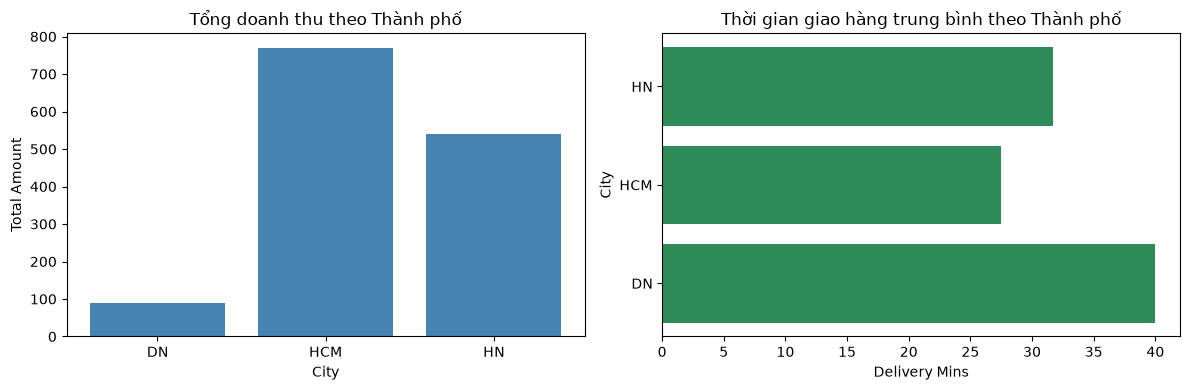

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(summary['City'], summary['Total_Amount'], color='steelblue')
axes[0].set_title('Tổng doanh thu theo Thành phố')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Total Amount')

axes[1].barh(summary['City'], summary['Avg_Delivery_Mins'], color='seagreen')
axes[1].set_title('Thời gian giao hàng trung bình theo Thành phố')
axes[1].set_xlabel('Delivery Mins')
axes[1].set_ylabel('City')

plt.tight_layout()
plt.show()